In [2]:
import yfinance as yf


TICKERS = ["AAPL", "GOOGL", "AMZN", "KO", "JNJ", "JPM", "XOM", "CAT", "NEE", "LIN"]


raw = yf.download(
    TICKERS,
    period="3y",
    interval="1d",
    auto_adjust=True,
    threads=True,
    progress=False,
)
close = raw["Close"]
returns = close.pct_change(fill_method=None).dropna(how="any")
returns.index.name = "Date"
returns.to_csv("returns.csv")

print(f"Saved {len(returns)} rows")

Saved 752 rows


In [ ]:
market_raw = yf.download(
    "^GSPC",
    period="3y",
    interval="1d",
    auto_adjust=True,
    threads=True,
    progress=False,
)
market_close = market_raw["Close"]["^GSPC"]
market_returns = market_close.pct_change(fill_method=None).dropna()
market_returns = market_returns.to_frame(name="^GSPC")
market_returns.index.name = "Date"
market_returns.to_csv("sp500_returns.csv")

print(f"Saved {len(market_returns)} rows")

In [2]:
import pandas as pd

returns = pd.read_csv("returns.csv", parse_dates=True, index_col="Date")
market_returns = pd.read_csv("sp500_returns.csv", parse_dates=True, index_col="Date")

risk_free = pd.read_csv("TB3MS.csv", parse_dates=True, index_col="observation_date")
risk_free = risk_free.reindex(returns.index, method="ffill")

daily_risk_free = (1 + risk_free["TB3MS"] / 100) ** (1 / 252) - 1

excess_returns = returns.sub(daily_risk_free, axis=0)
market_excess_returns = market_returns.sub(daily_risk_free, axis=0)

In [3]:
from statsmodels.regression.rolling import RollingOLS


window = 252
market_excess = market_excess_returns.iloc[:, 0]
X = pd.DataFrame(
    {"intercept": 1.0, "market": market_excess},
    index=market_excess.index,
)

rolling_capm = []
for ticker in excess_returns.columns:
    y = excess_returns[ticker]
    fitted = RollingOLS(y, X, window=window).fit()
    params = fitted.params.rename(columns={"intercept": "Alpha", "market": "Beta"})
    params["Alpha_pvalue"] = fitted.pvalues[:, 0]
    params.insert(0, "Ticker", ticker)
    params = params.dropna(subset=["Alpha", "Beta", "Alpha_pvalue"])
    rolling_capm.append(params)

rolling_capm = pd.concat(rolling_capm)

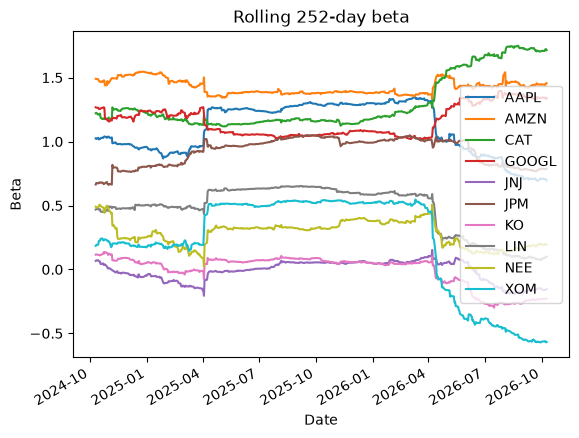

Latest rolling-window alpha significance (unadjusted p-values):


,Date,p-value,Daily alpha (%),Significant (5%)
Ticker,,,,
XOM,2026-10-09,0.051640,0.192999,False
JNJ,2026-10-09,0.073673,0.136311,False
KO,2026-10-09,0.085092,0.127356,False
CAT,2026-10-09,0.344400,0.126040,False
GOOGL,2026-10-09,0.403177,0.087832,False
AAPL,2026-10-09,0.430204,0.072132,False
NEE,2026-10-09,0.654594,-0.036542,False
LIN,2026-10-09,0.928403,0.006846,False
JPM,2026-10-09,0.975176,0.002471,False


In [ ]:
import matplotlib.pyplot as plt


beta = rolling_capm.pivot(columns="Ticker", values="Beta")
ax = beta.plot()
ax.set_title("Rolling 252-day beta")
ax.set_xlabel("Date")
ax.set_ylabel("Beta")
ax.legend(loc="center right")
plt.show()


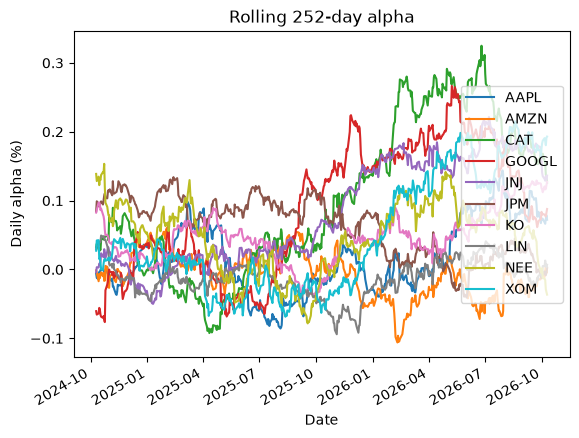

In [11]:
alpha = rolling_capm.pivot(columns="Ticker", values="Alpha") * 100
ax = alpha.plot()
ax.set_title("Rolling 252-day alpha")
ax.set_xlabel("Date")
ax.set_ylabel("Daily alpha (%)")
ax.legend(loc="center right")
plt.show()


In [9]:
latest_date = rolling_capm.index.max()
latest_alpha_pvalues = rolling_capm.loc[
    rolling_capm.index == latest_date, ["Ticker", "Alpha_pvalue"]
]
latest_alpha_pvalues["Significant"] = latest_alpha_pvalues["Alpha_pvalue"] < 0.05
display(latest_alpha_pvalues)

,Ticker,Alpha_pvalue,Significant
Date,,,
2026-10-09,AAPL,0.430204,False
2026-10-09,AMZN,0.990371,False
2026-10-09,CAT,0.344400,False
2026-10-09,GOOGL,0.403177,False
2026-10-09,JNJ,0.073673,False
2026-10-09,JPM,0.975176,False
2026-10-09,KO,0.085092,False
2026-10-09,LIN,0.928403,False
2026-10-09,NEE,0.654594,False


## Interpreting the CAPM Results

Technology companies including AAPL, AMZN, and GOOGL generally have higher betas, so their returns are more sensitive to market movements. JNJ and KO generally have lower betas, so their returns are less affected by the market. There are large beta movements around April 2025, which shows that the U.S. tariff announcements on April 2, 2025 have an impact on the betas of rolling windows including it. None of the alphas for the latest windows are statistically significant.